# Payment Instrument Performance Analysis
How does each payment instrument perform in terms of size, transaction value, growth and stability?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path("../Data/Cleaned/Nepal_Online_Payment_System.csv")

df = pd.read_csv(DATA_PATH)
df["period_end"] = pd.to_datetime(df["period_end"])

nepali_month_order = [
    "Baisakh", "Jestha", "Asar", "Saun",
    "Bhadau", "Asoj", "Kartik", "Mangsir",
    "Pus", "Magh", "Falgun", "Chaitra"
]

df["bs_month"] = pd.Categorical(
    df["bs_month"],
    categories=nepali_month_order,
    ordered=True
)

df.shape

(645, 11)

### What data is available for each instrument?

In [2]:
total_months = df["period_end"].nunique()

instrument_profile = (
    df.groupby(["category", "instrument"])
    .agg(
        first_month=("period_end", "min"),
        last_month=("period_end", "max"),
        months_reported=("period_end", "nunique"),
        flagged_months=("is_flagged", "sum")
    )
    .reset_index()
    .sort_values(["category", "instrument"])
)

instrument_profile["coverage_pct"] = (
    instrument_profile["months_reported"] / total_months * 100
).round(1)

instrument_profile

,category,instrument,first_month,last_month,months_reported,flagged_months,coverage_pct
0,Banking channels,Branchless Banking,2023-07-01,2026-10-01,40,0,100.0
1,Banking channels,Internet Banking,2023-07-01,2026-10-01,40,1,100.0
2,Banking channels,Mobile Banking,2023-07-01,2026-10-01,40,1,100.0
3,Cards,Credit Cards,2023-07-01,2026-10-01,40,0,100.0
4,Cards,Debit Cards,2023-07-01,2026-10-01,40,0,100.0
5,Cards,Prepaid Cards,2023-07-01,2026-10-01,40,0,100.0
6,Cash,ATM Cash Withdrawal,2023-07-01,2026-10-01,40,0,100.0
7,Clearing,ECC (Cheque Clearing),2023-07-01,2026-10-01,40,0,100.0
8,Instant payments,Faster Payment Systems,2023-07-01,2026-10-01,31,0,77.5
9,Interbank / large value,RTGS,2023-07-01,2026-10-01,40,0,100.0


### Observations: Data coverage
1. The dataset has 17 payment instruments in 10 categories, covering 40 months (Jul 2023 to Oct 2026). All of them are still reporting in the latest month.
2. 14 instruments have complete coverage (40 months).
3. Three instruments have gaps: Faster Payment Systems (31 months, missing Aug 2023 to Apr 2024), Other Retail Payments (29 months, missing Aug 2023 to Jun 2024) and Cross Border QR Acquiring (25 months, started in Oct 2024). Their historical totals and growth cannot be compared directly with the other instruments.
4. 12 months are flagged: IPS has 10 (count spikes), Mobile Banking has 1 (source revision in Nov 2023) and Internet Banking has 1 (large amount drop in Oct 2026, possibly preliminary).
5. Because of these gaps, comparisons of current size use the last 12 months (all 17 instruments report), and growth comparisons are made carefully for the three partial instruments.

### Which instruments matter most today? (last 12 months)
The last 12 months (Nov 2025 to Oct 2026) are used because all 17 instruments report in that period, so there are no gaps or partial years to distort the comparison.

In [3]:
latest_month = df["period_end"].max()
start_month = latest_month - pd.DateOffset(months=11)

recent = df[df["period_end"] >= start_month]

recent_summary = (
    recent.groupby(["category", "instrument"])
    .agg(
        months=("period_end", "nunique"),
        total_txn_count=("txn_count", "sum"),
        total_amount_npr_million=("txn_amount_npr_million", "sum")
    )
    .reset_index()
)

recent_summary["count_share_pct"] = (
    recent_summary["total_txn_count"] / recent_summary["total_txn_count"].sum() * 100
)
recent_summary["amount_share_pct"] = (
    recent_summary["total_amount_npr_million"] / recent_summary["total_amount_npr_million"].sum() * 100
)

recent_summary["total_count_million"] = recent_summary["total_txn_count"] / 1_000_000
recent_summary["total_amount_npr_trillion"] = recent_summary["total_amount_npr_million"] / 1_000_000

recent_summary = recent_summary.sort_values("count_share_pct", ascending=False)

recent_summary[
    ["category", "instrument", "months", "total_count_million",
     "count_share_pct", "total_amount_npr_trillion", "amount_share_pct"]
].round(2)

,category,instrument,months,total_count_million,count_share_pct,total_amount_npr_trillion,amount_share_pct
2,Banking channels,Mobile Banking,12,859.26,30.53,6.94,5.18
15,Wallet & QR,QR-Based Payments,12,694.53,24.68,1.81,1.35
16,Wallet & QR,Wallet,12,573.69,20.39,0.61,0.45
8,Instant payments,Faster Payment Systems,12,237.22,8.43,6.79,5.06
13,Other retail,Other Retail Payments,12,134.83,4.79,7.64,5.70
4,Cards,Debit Cards,12,121.09,4.30,0.94,0.70
6,Cash,ATM Cash Withdrawal,12,114.69,4.08,0.91,0.68
10,Interbank / retail,IPS,12,35.99,1.28,3.67,2.74
7,Clearing,ECC (Cheque Clearing),12,13.32,0.47,6.84,5.10
12,Merchant & e-commerce,Point of Sales (POS),12,8.99,0.32,0.05,0.04


### Observations: Instrument size (last 12 months, Nov 2025 to Oct 2026)
1. Three instruments carry most of the transaction count: Mobile Banking (30.53%), QR-Based Payments (24.68%) and Wallet (20.39%), together 75.60%. Adding Faster Payment Systems (8.43%) brings the top four to about 84%.
2. RTGS carries 72.74% of the transaction amount (NPR 97.55 trillion) with only 0.03% of the count (0.86 million transactions).
3. After RTGS, value is spread fairly evenly: Other Retail Payments (5.70%), Mobile Banking (5.18%), ECC (5.10%) and Faster Payment Systems (5.06%).
4. Count and value rankings are very different. Mobile Banking, QR and Wallet lead by count but together hold only about 7% of the amount, while ECC has just 0.47% of the count but 5.10% of the amount.
5. Compared with the full-period shares in notebook 02 (a different period, so indicative), QR-Based Payments has risen (19.67% to 24.68% of count), while Mobile Banking (31.56% to 30.53%) and Wallet (20.95% to 20.39%) have slipped slightly.

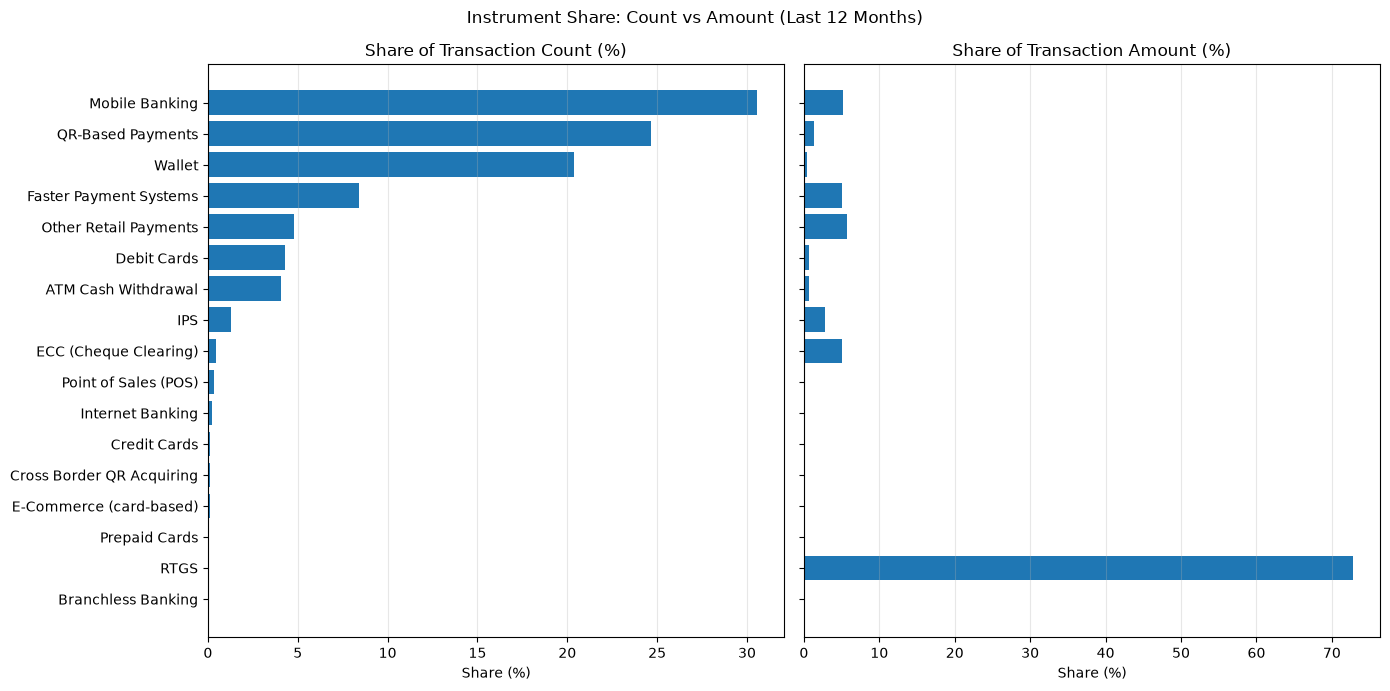

In [4]:
plot_df = recent_summary.sort_values("count_share_pct")

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)

axes[0].barh(plot_df["instrument"], plot_df["count_share_pct"])
axes[0].set_title("Share of Transaction Count (%)")
axes[0].set_xlabel("Share (%)")

axes[1].barh(plot_df["instrument"], plot_df["amount_share_pct"])
axes[1].set_title("Share of Transaction Amount (%)")
axes[1].set_xlabel("Share (%)")

for ax in axes:
    ax.grid(axis="x", alpha=0.3)

plt.suptitle("Instrument Share: Count vs Amount (Last 12 Months)")
plt.tight_layout()
plt.show()